## Do your best

In [1]:
import joblib
import numpy
from comet_ml import Experiment
import os
from util.data_aquisition import generate
from util.engineered_data_frame import engineered_data_frame

In [2]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2015-2016
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2018-2019


In [3]:
df = engineered_data_frame(data)

/Users/nassimwalha/Desktop/IFT-6758/notebooks/util/engineered_data_frame.py:75: RuntimeWarning: invalid value encountered in double_scalars
  return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))


In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import metrics
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from util.metrics_visualization import generate_four_curves

In [5]:
selected_features = ["Period", "Period_Time_Seconds", "Distance_Net", "Angle", "X_Coordinate", "Speed",
                     "Friendly_Non_Goalies", "Opponent_Non_Goalies", "Shoot_Type"]
df_features = df[selected_features]
df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)
df = df_features
df.info()

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_18289/4011370545.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311106 entries, 0 to 311105
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Period                311106 non-null  int64  
 1   Period_Time_Seconds   311106 non-null  int64  
 2   Distance_Net          311086 non-null  float64
 3   Angle                 311085 non-null  float64
 4   X_Coordinate          311088 non-null  float64
 5   Speed                 306112 non-null  float64
 6   Friendly_Non_Goalies  311106 non-null  int64  
 7   Opponent_Non_Goalies  311106 non-null  int64  
 8   Shoot_Type            311068 non-null  object 
 9   is_goal               311106 non-null  int64  
dtypes: float64(4), int64(5), object(1)
memory usage: 23.7+ MB


In [6]:
df = df.dropna()
df = df[df.Speed!=np.inf]

In [7]:
df.is_goal.value_counts()

0    273317
1     27173
Name: is_goal, dtype: int64

In [8]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,:-1], df.iloc[:,-1], test_size = 0.20, random_state=42,
                                                    stratify=df.iloc[:,-1])
features_to_standardize = ["Period", "Period_Time_Seconds", "Distance_Net", "Angle", "X_Coordinate", "Speed"]
features_one_hot = ['Shoot_Type']
my_transformer = ColumnTransformer([('standard', StandardScaler(), features_to_standardize),
                                    ('one-hot', OneHotEncoder(), features_one_hot)],
                                   remainder='passthrough')
X_train = my_transformer.fit_transform(X_train)
X_test = my_transformer.transform(X_test)
y_test.reset_index(inplace= True, drop=True)
y_train.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period', 'standard__Period_Time_Seconds',
       'standard__Distance_Net', 'standard__Angle',
       'standard__X_Coordinate', 'standard__Speed',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'remainder__Friendly_Non_Goalies',
       'remainder__Opponent_Non_Goalies'], dtype=object)

#### Train with balanced classes: Undersampling

Une particularité de notre ensemble des données est le fait que les classes sont trop non-balancées. Il y a 10 fois plus de Shot que de Goal. Une idée qui pourrait améliorer la performance est de faire l'entraînement avec des classes balancées. Pour la validation (ici X_test, y_test), on doit garder la même distribution des données, car c'est un proxy de la distribution réelle des données. Pour l'entrainement, on inclue la totalité des points de données de la classe minoritaire, et on ajoute le même nombre de points de données de la classe majoritaire choisis au hazard. Le problème c'est qu'une grande quantité des données ne va pas être utilisée. Nous espérons que ce ne soit pas un grand problème.

In [17]:
def find_indices(value_to_find, array):
    res = []
    for idx, value in enumerate(array):
        if value==value_to_find:
            res.append(idx)
    return res


In [18]:
ones_indices = np.array(find_indices(1, y_train))
zeros_indices = np.array(find_indices(0,y_train))
np.random.seed(42)
chosen_zeros_indices = np.random.permutation(zeros_indices)[:len(ones_indices)]
selected_indices = np.hstack((ones_indices,chosen_zeros_indices))
selected_indices = np.random.permutation(selected_indices)
X_train_balanced = X_train[selected_indices,:]
y_train_balanced = y_train[selected_indices]

In [19]:
y_train_balanced.value_counts()

1    21738
0    21738
Name: is_goal, dtype: int64

In [20]:
import xgboost as xgb

In [21]:
#exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
#exp.add_tag("XGBOOST Balanced Set")
# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier()#tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train_balanced, y_train_balanced)

print('Accuracy on training data: ', round(model_xgb.score(X_train_balanced,y_train_balanced),2))
result_xgb = model_xgb.score(X_test,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/4d8a25552fc2407781aab2d20ac5fe6c

COMET WARNING: You must install graphviz to plot tree


Accuracy on training data:  0.75
Accuracy on testing data:  64.23


f1 score: 0.51616916142474


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/4d8a25552fc2407781aab2d20ac5fe6c
COMET INFO:   Metrics:
COMET INFO:     accuracy : 0.6423341874937601
COMET INFO:     auc      : 0.7372821234453185
COMET INFO:     f1_score : 0.51616916142474
COMET INFO:   Parameters:
COMET INFO:     begin_iteration : 0
COMET INFO:     end_iteration   : 99
COMET INFO:     objective       : binary:logistic
COMET INFO:     rank            : 0
COMET INFO:     world_size      : 1
COMET INFO:   Uploads:
COMET INFO:     conda-environment-definition : 1
COMET INFO:     conda-info                   : 1
COMET INFO:     conda-specification          : 1
COMET INFO:     environment details          : 1
COMET INFO:     filename                     : 1
COMET INFO:     git metadata                 : 1

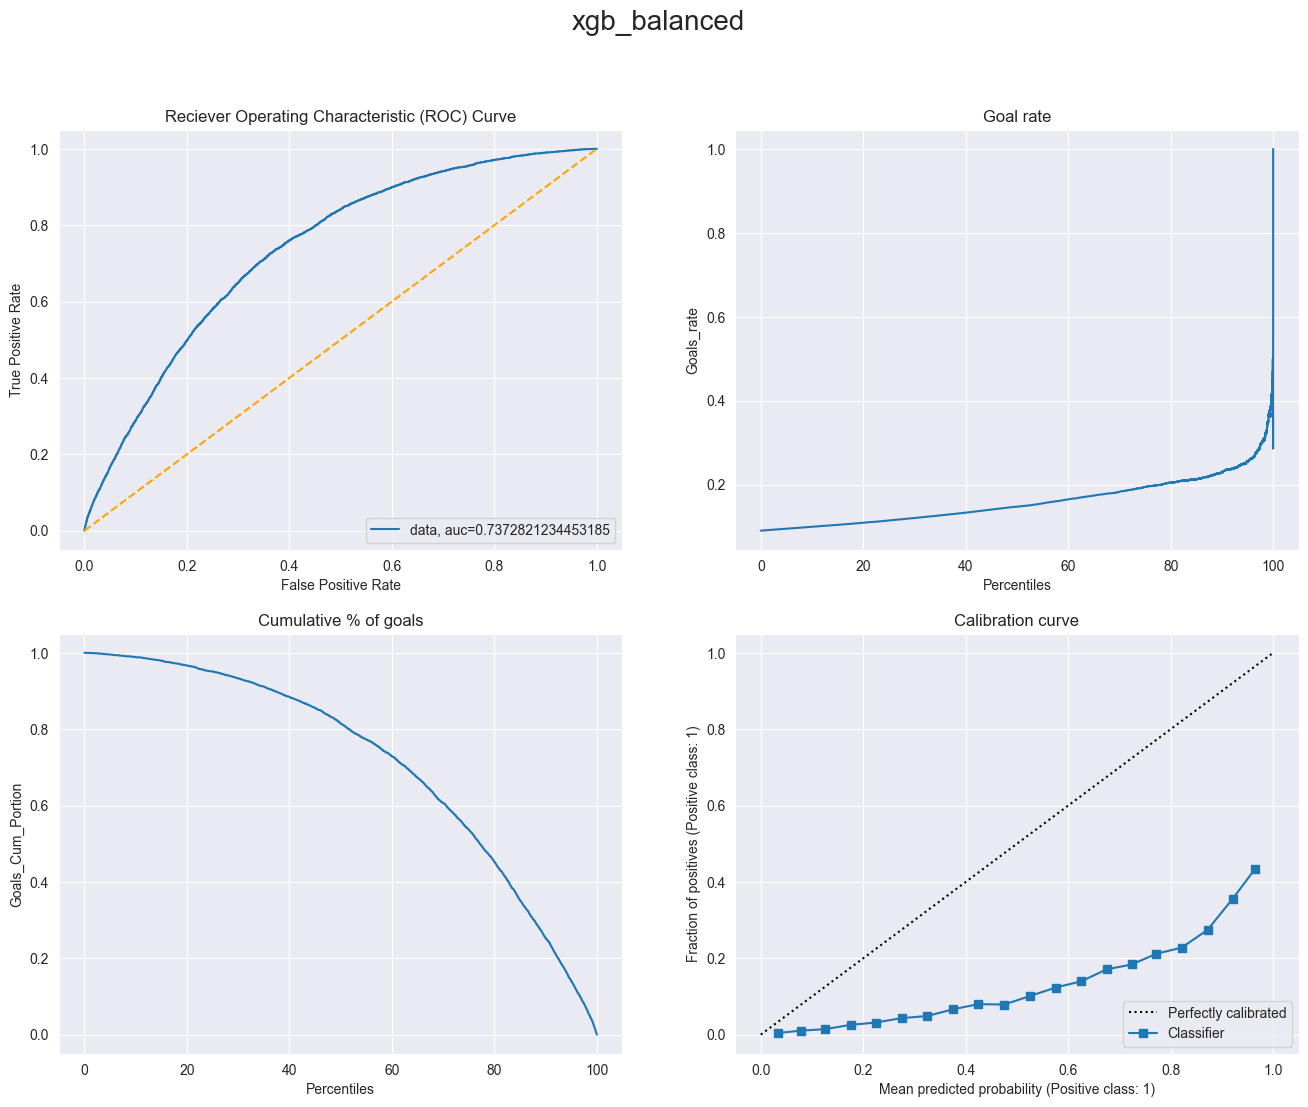

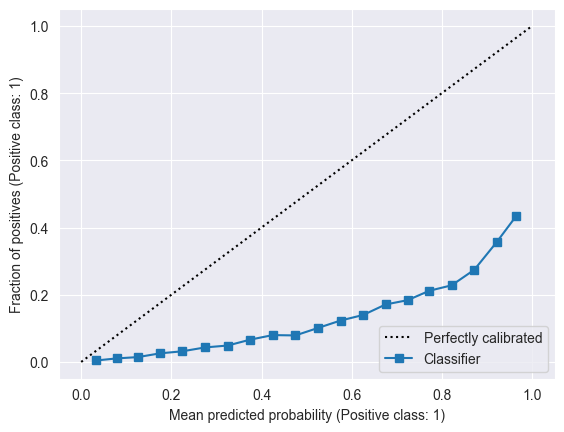

In [22]:
fig = generate_four_curves("xgb_balanced", y_test, classi.predict_proba(X_test)[:,1], 20)

f1 = metrics.f1_score(y_test, classi.predict(X_test), average='macro')
print(f"f1 score: {f1}")
auc = metrics.roc_auc_score(y_test, classi.predict_proba(X_test)[:,1])
#exp.log_metric("accuracy", result_xgb)
#exp.log_metric("f1_score", f1)
#exp.log_metric("auc", auc)
#model_xgb.save_model("models/xgb_balanced.json")
#exp.log_model("XGB Balanced", "models/xgb_balanced.json")
#exp.end()

In [23]:
print(metrics.classification_report(y_test, classi.predict(X_test)))

              precision    recall  f1-score   support

           0       0.96      0.63      0.76     54663
           1       0.17      0.73      0.27      5435

    accuracy                           0.64     60098
   macro avg       0.56      0.68      0.52     60098
weighted avg       0.89      0.64      0.72     60098



Conclusion: l'exactitude est inférieure aux expériences précédentes (64% vs 90%). Ceci est dû au fait que notre modèle ne prédit pas systématiquement des non-buts. En contre-partie le score f1 s'est légèrement élevé (0.52 vs 0.49): On a une précision meilleure pour la classe minoritaire. Le grand problème c'est la calibration qui devient très mauvaise, donc on décide de laisser tomber cette méthode.

#### Use a new metric for hyperparameter search

La dernière expérience nous a montré qu'on peut améliorer la performance du modèle en terme de score f1 et auc, mais on risque de perdre la calibration, qui est pourtant un objectif très important pour pouvoir prédire les buts espérés. Pour faire une recherche d'Hyperpararamètres qui nous donne le modèle le plus calibré, on a besoin de créer un score de calibration. Un score qui reflète bien la courbe de calibration est le Expected Calibration Error (ECE) (en négatif, vu que c'est un erreur). La courbe de calibration est en fait construite comme suit: On prend les probabilité prédites par le modèle et on les met dans des bins. Dans chaque bin on calcule la moyenne des probabilités prédites (axe des x) et la probabilité réelle des buts (n_buts/(n_buts+n_pas_buts)) dans le bin (axe des y). La courbe de calibration est alors la courbe qui passe par ces points, et devrait idéalement être superposée à la droite d'équation y=x. Dans ce contexte le ECE est la moyenne des différences en valeur absolue entre la probabilité prédite et la probabilité réelle dans chaque bin, pondérée par la taille des bins. En formules c'est égal à $$ ECE = \sum_{b=1}^{N_{bins}}\frac{n_b}{N}|avg\_predicted\_prob(bin_b)-goal\_rate(bin_b)| $$

In [11]:
def my_calibration_scorer(estimator,
                      X,
                      y,
                      n_bins=20
):
    """
    Implements the Expexted Calibration Error
    """

    y_prob = estimator.predict_proba(X)[:,1]

    bins = np.linspace(0.0, 1.0, n_bins + 1)

    binids = np.searchsorted(bins[1:-1], y_prob)

    bin_sums = np.bincount(binids, weights=y_prob, minlength=len(bins))
    bin_true = np.bincount(binids, weights=y, minlength=len(bins))
    bin_total = np.bincount(binids, minlength=len(bins))

    nonzero = bin_total != 0
    prob_true = bin_true[nonzero] / bin_total[nonzero]
    prob_pred = bin_sums[nonzero] / bin_total[nonzero]
    calibration_error = np.sum(np.abs(prob_true - prob_pred) * (bin_total[nonzero] / len(y)))

    return -calibration_error

In [18]:
from sklearn.model_selection import RandomizedSearchCV

tuned_parameters = {
  'gamma': np.linspace(0, 3, num=70),
  'max_depth': np.linspace(0, 10, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11),

  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=250, scoring=my_calibration_scorer, cv=5,
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [19]:
print("Meilleur ensemble de paramètres trouvé")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé

{'max_depth': 6, 'max_delta_step': 0.0, 'gamma': 1.9565217391304348}
-0.0035781585518995275


Meilleur ensemble de paramètres trouvé

{'max_depth': 6, 'max_delta_step': 0.0, 'gamma': 1.9565217391304348}
-0.0035781585518995275

In [26]:
#model = grid_search.best_estimator_
exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
exp.add_tag("XGBOOST Tuned on ECE")
model = xgb.XGBClassifier( max_delta_step = 0, gamma=1.9565217391304348)#, tree_method='gpu_hist')
model.fit(X_train, y_train)
print('Accuracy on training data: ', round(model.score(X_train,y_train),2))
result = model.score(X_test,y_test)
print('Accuracy on testing data: ', round(result*100,2))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/d5960f58e1fc45d3ba595d83ea73798f



Accuracy on training data:  0.91
Accuracy on testing data:  91.01


f1 score: 0.4944289095932768
 ece: 0.005351475662496855


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/d5960f58e1fc45d3ba595d83ea73798f
COMET INFO:   Metrics:
COMET INFO:     Exp. Pred. Error : 0.005351475662496855
COMET INFO:     accuracy         : 0.9100635628473493
COMET INFO:     auc              : 0.7466802704691475
COMET INFO:     f1_score         : 0.4944289095932768
COMET INFO:   Parameters:
COMET INFO:     begin_iteration : 0
COMET INFO:     end_iteration   : 99
COMET INFO:     gamma           : 1.9565217391304348
COMET INFO:     max_delta_step  : 0
COMET INFO:     objective       : binary:logistic
COMET INFO:     rank            : 0
COMET INFO:     world_size      : 1
COMET INFO:   Uploads:
COMET INFO:     conda-environment-definition : 1
COMET INFO:     conda-info                   : 1
COMET INFO:     conda-sp

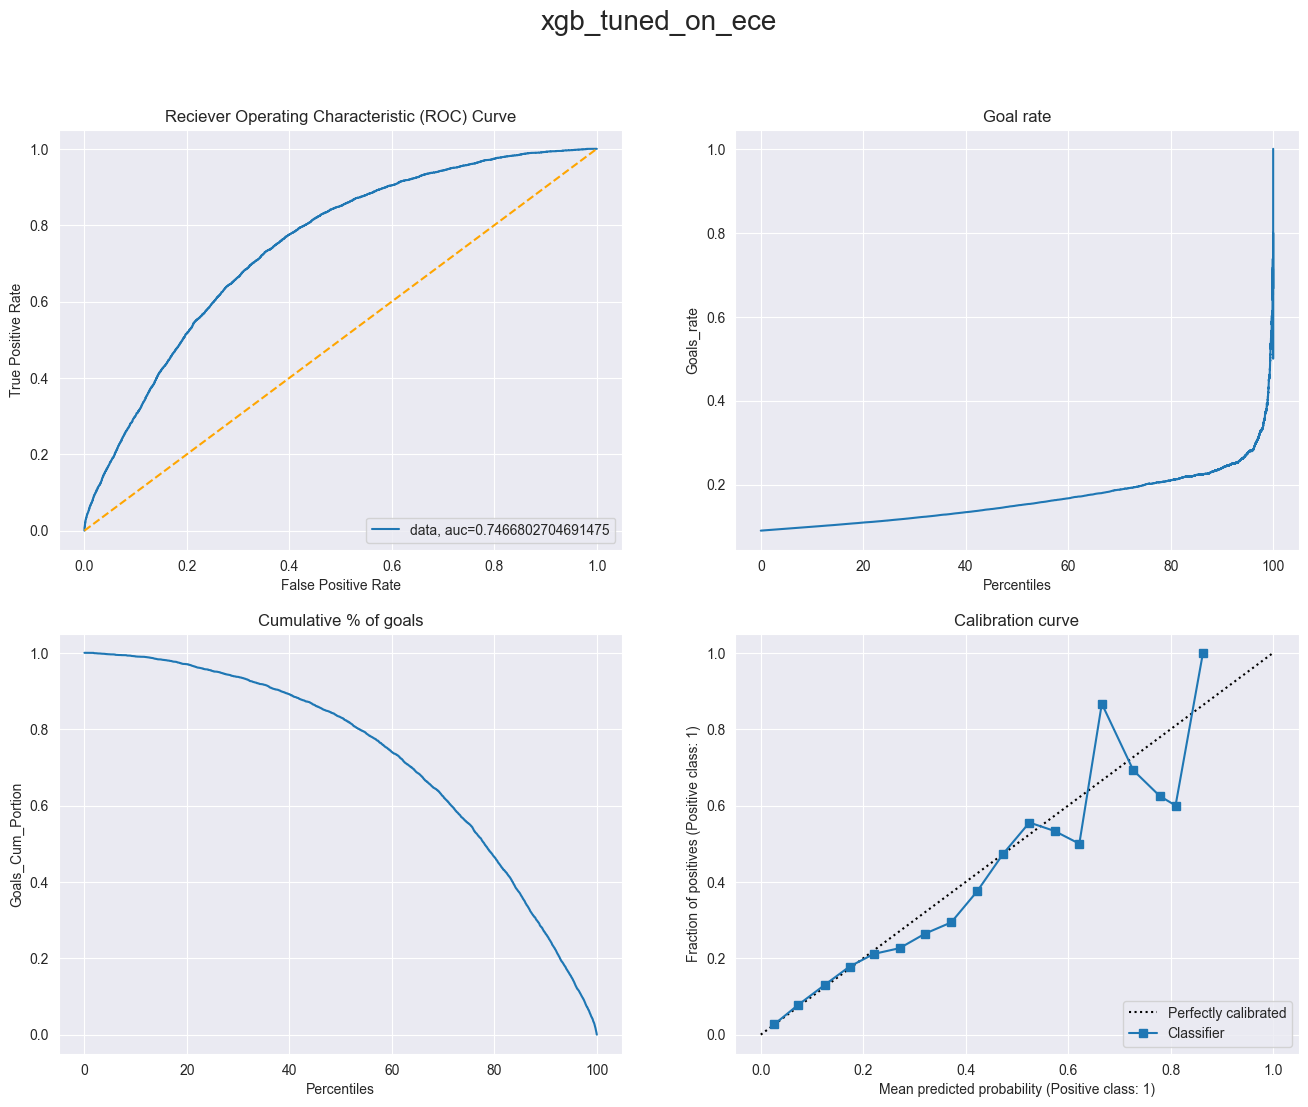

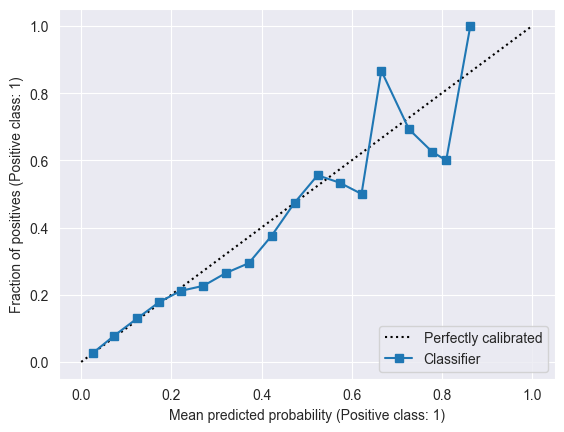

In [27]:
fig = generate_four_curves("xgb_tuned_on_ece", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
exp.log_metric("accuracy", result)
exp.log_metric("f1_score", f1)
exp.log_metric("auc", auc)
exp.log_metric("Exp. Pred. Error", ece)
model.save_model("models/xgb_tuned_on_ece.json")
exp.log_model("XGB Tuned on ECE", "models/xgb_tuned_on_ece.json")
exp.end()

En utilisant -ECE comme score à optimiser pour la recherche d'hyperparamètres, on trouve une courbe da calibration bien meilleure que celle qu'on a trouvée pour le dernier modèle de Advanced Models (modèle xboost tuné avec les caractéristiques sélectionnées). Rappelons que la courbe de calibration s'est déteriorée quand on a fait la sélection des caractéristiques. En utilisant -ECE comme critère de recherche, on a pu rattrapé cette déterioration en gardant que les caractéristiques sélectionnées. On décide donc d'utiliser ce score pour les prochaines expériences de recherche d'Hyperparamètres.

#### Different model: LDA

En essayant plusieurs méthodes pour améliorer les prédictions de XGBOOST, il semble qu'on ne peut plus réaliser des grandes améliorations. C'est pour cela qu'on décide d'expérimenter avec d'autres modèles probabilistes de classification. On commence avec LDA et QDA (Linear and Quadratic discriminant analysis). Les résulats sont très décevants et même moins bons que ceux de la regréssion logistique. On remarque qu'on remonte à un ECE de 0.34 dans le cas de QDA ce qui montre une très mauvaise calibration.

In [35]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [40]:
#model = grid_search.best_estimator_
exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
exp.add_tag("LDA")

model = LinearDiscriminantAnalysis()
model.fit(X_train, y_train)
print('Accuracy on training data: ', round(model.score(X_train,y_train),2))
result = model.score(X_test,y_test)
print('Accuracy on testing data: ', round(result*100,2))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/0898782ee26549b6a4f1e79ba43e37e7



Accuracy on training data:  0.91
Accuracy on testing data:  90.93


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/0898782ee26549b6a4f1e79ba43e37e7
COMET INFO:   Metrics:
COMET INFO:     Exp. Pred. Error : 0.008932441435797448
COMET INFO:     accuracy         : 0.9093314253386136
COMET INFO:     auc              : 0.6653453280122459
COMET INFO:     f1_score         : 0.47662240273685147
COMET INFO:   Parameters:
COMET INFO:     covariance_estimator : 1
COMET INFO:     n_components         : 1
COMET INFO:     priors               : 1
COMET INFO:     shrinkage            : 1
COMET INFO:     solver               : svd
COMET INFO:     store_covariance     : False


f1 score: 0.47662240273685147
 ece: 0.008932441435797448


COMET INFO:     tol                  : 0.0001
COMET INFO:   Uploads:
COMET INFO:     conda-environment-definition : 1
COMET INFO:     conda-info                   : 1
COMET INFO:     conda-specification          : 1
COMET INFO:     environment details          : 1
COMET INFO:     filename                     : 1
COMET INFO:     git metadata                 : 1
COMET INFO:     git-patch (uncompressed)     : 1 (1.93 MB)
COMET INFO:     installed packages           : 1
COMET INFO:     model-element                : 1 (1.63 KB)
COMET INFO:     notebook                     : 1
COMET INFO:     source_code                  : 1
COMET INFO: ---------------------------
COMET INFO: Uploading 1 metrics, params and output messages


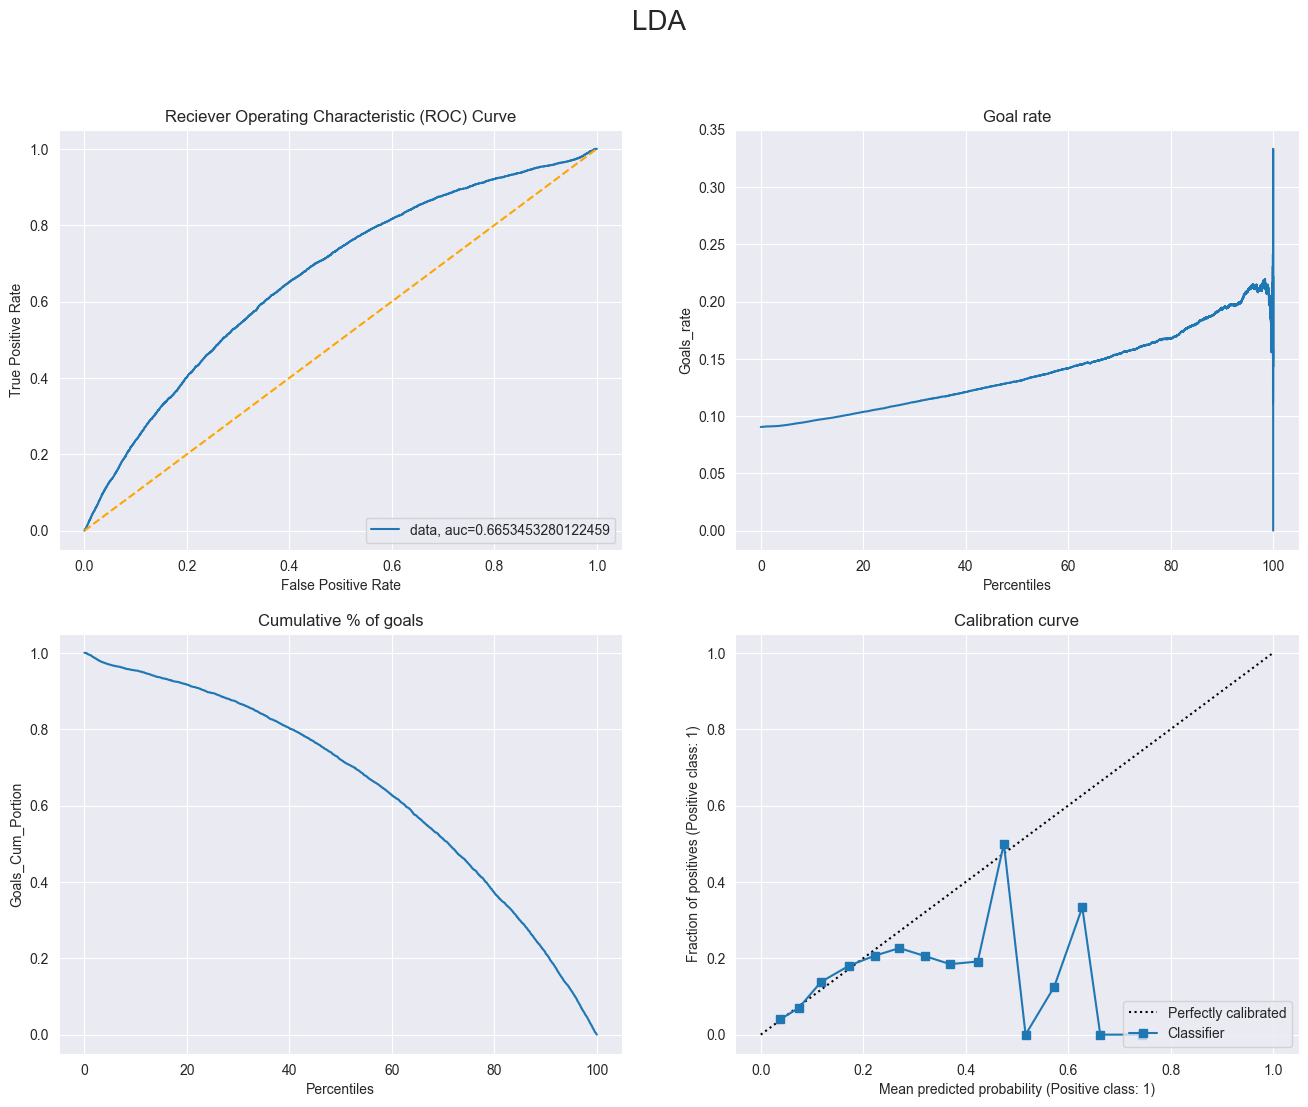

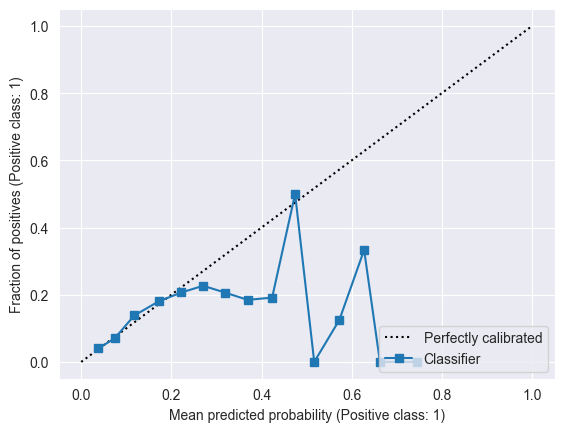

In [41]:
fig = generate_four_curves("LDA", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece: {ece}")
auc = metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
exp.log_metric("accuracy", result)
exp.log_metric("f1_score", f1)
exp.log_metric("auc", auc)
exp.log_metric("Exp. Pred. Error", ece)
joblib.dump(model, "models/LDA.joblib")
exp.log_model("LDA", "models/LDA.joblib")
exp.end()

#### Different model: QDA

In [42]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

In [43]:
#model = grid_search.best_estimator_
exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
exp.add_tag("QDA")

model = QuadraticDiscriminantAnalysis()
model.fit(X_train, y_train)
print('Accuracy on training data: ', round(model.score(X_train,y_train),2))
result = model.score(X_test,y_test)
print('Accuracy on testing data: ', round(result*100,2))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/b93d8ce8d5a84e63875d6246f75ea7fc

/Users/nassimwalha/opt/miniconda3/envs/project/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:887: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


Accuracy on training data:  0.63
Accuracy on testing data:  62.9


f1 score: 0.46922043655790047
 ece score: 0.3404711737643953


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/b93d8ce8d5a84e63875d6246f75ea7fc
COMET INFO:   Metrics:
COMET INFO:     Exp. Pred. Error : 0.3404711737643953
COMET INFO:     accuracy         : 0.6290059569370029
COMET INFO:     auc              : 0.5687838408934053
COMET INFO:     f1_score         : 0.46922043655790047
COMET INFO:   Parameters:
COMET INFO:     priors           : 1
COMET INFO:     reg_param        : 0.0
COMET INFO:     store_covariance : False
COMET INFO:     tol              : 0.0001
COMET INFO:   Uploads:
COMET INFO:     conda-environment-definition : 1
COMET INFO:     conda-info                   : 1
COMET INFO:     conda-specification          : 1
COMET INFO:     environment details          : 1
COMET INFO:     filename                     : 1
COM

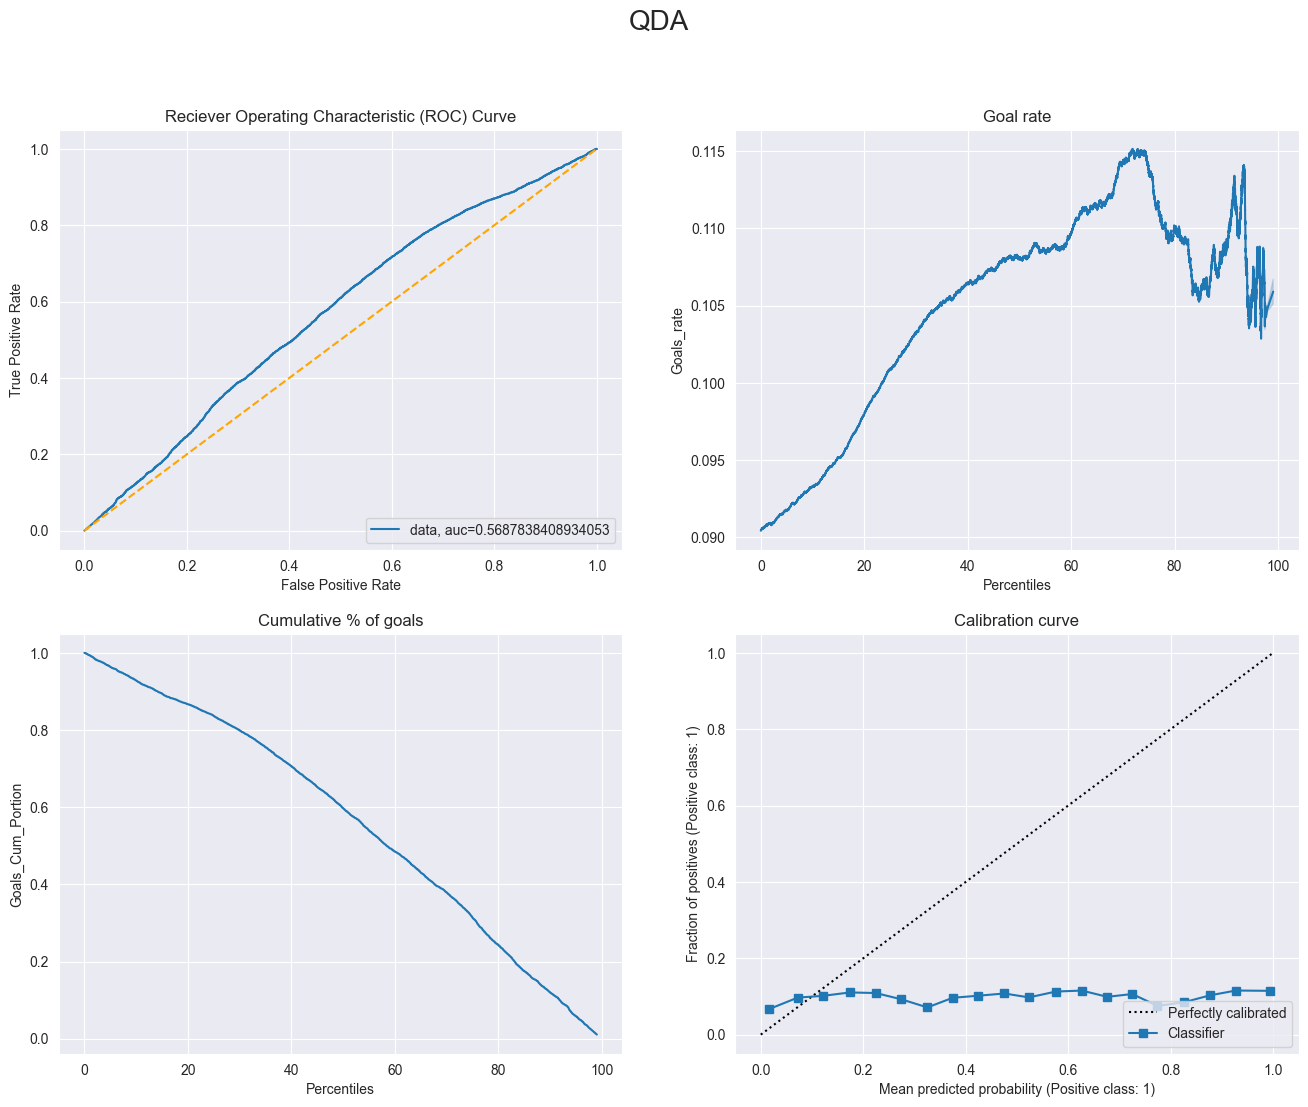

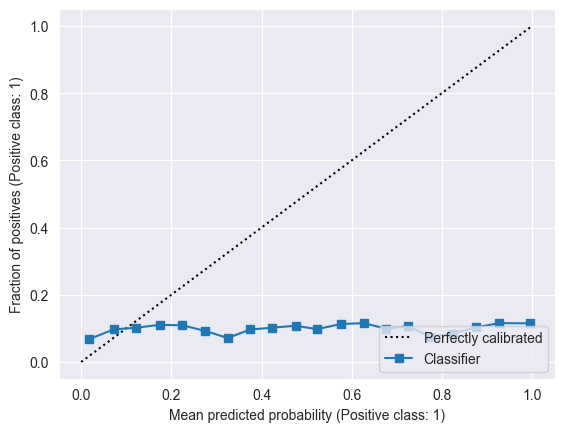

In [44]:
fig = generate_four_curves("QDA", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece score: {ece}")
auc = metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
exp.log_metric("accuracy", result)
exp.log_metric("f1_score", f1)
exp.log_metric("auc", auc)
exp.log_metric("Exp. Pred. Error", ece)
joblib.dump(model, "models/QDA.joblib")
exp.log_model("QDA", "models/QDA.joblib")
exp.end()

#### New Model: Random forest classifier

Comme les deux derniers modèles n'ont pas été un succès, on retourne aux modèles ensemblistes en espérant faire mieux qu'avec XGBOOST.

In [45]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
from sklearn.model_selection import GridSearchCV

tuned_parameters = {
    "n_estimators": np.linspace(50,200, 4, dtype=int),
    "min_samples_leaf": np.linspace(1,4, 4, dtype=int)
}

grid_search = GridSearchCV(
    RandomForestClassifier(), tuned_parameters,  scoring=my_calibration_scorer, cv=5,
)
grid_search.fit(X_train, y_train);




In [ ]:
print('Finished!')
print("Meilleur ensemble de paramètres trouvé")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé
{‘n_estimators’: 200, ‘min_samples_leaf': 5} -0.0069

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/590894f49b474ba0b283ba3a46db5c0e



Accuracy on training data:  0.91
Accuracy on testing data:  90.99
f1 score: 0.4838592734162533
ece: 0.006806080850836855


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/590894f49b474ba0b283ba3a46db5c0e
COMET INFO:   Metrics:
COMET INFO:     Exp. Pred. Error : 0.006806080850836855
COMET INFO:     accuracy         : 0.9099138074478352
COMET INFO:     auc              : 0.7364294909205406
COMET INFO:     f1_score         : 0.4838592734162533
COMET INFO:   Parameters:
COMET INFO:     bootstrap                : True
COMET INFO:     ccp_alpha                : 0.0
COMET INFO:     class_weight             : 1
COMET INFO:     criterion                : gini
COMET INFO:     max_depth                : 1
COMET INFO:     max_features             : sqrt
COMET INFO:     max_leaf_nodes           : 1
COMET INFO:     max_samples              : 1
COMET INFO:     min_impurity_decrease    : 0.0
COMET INFO:

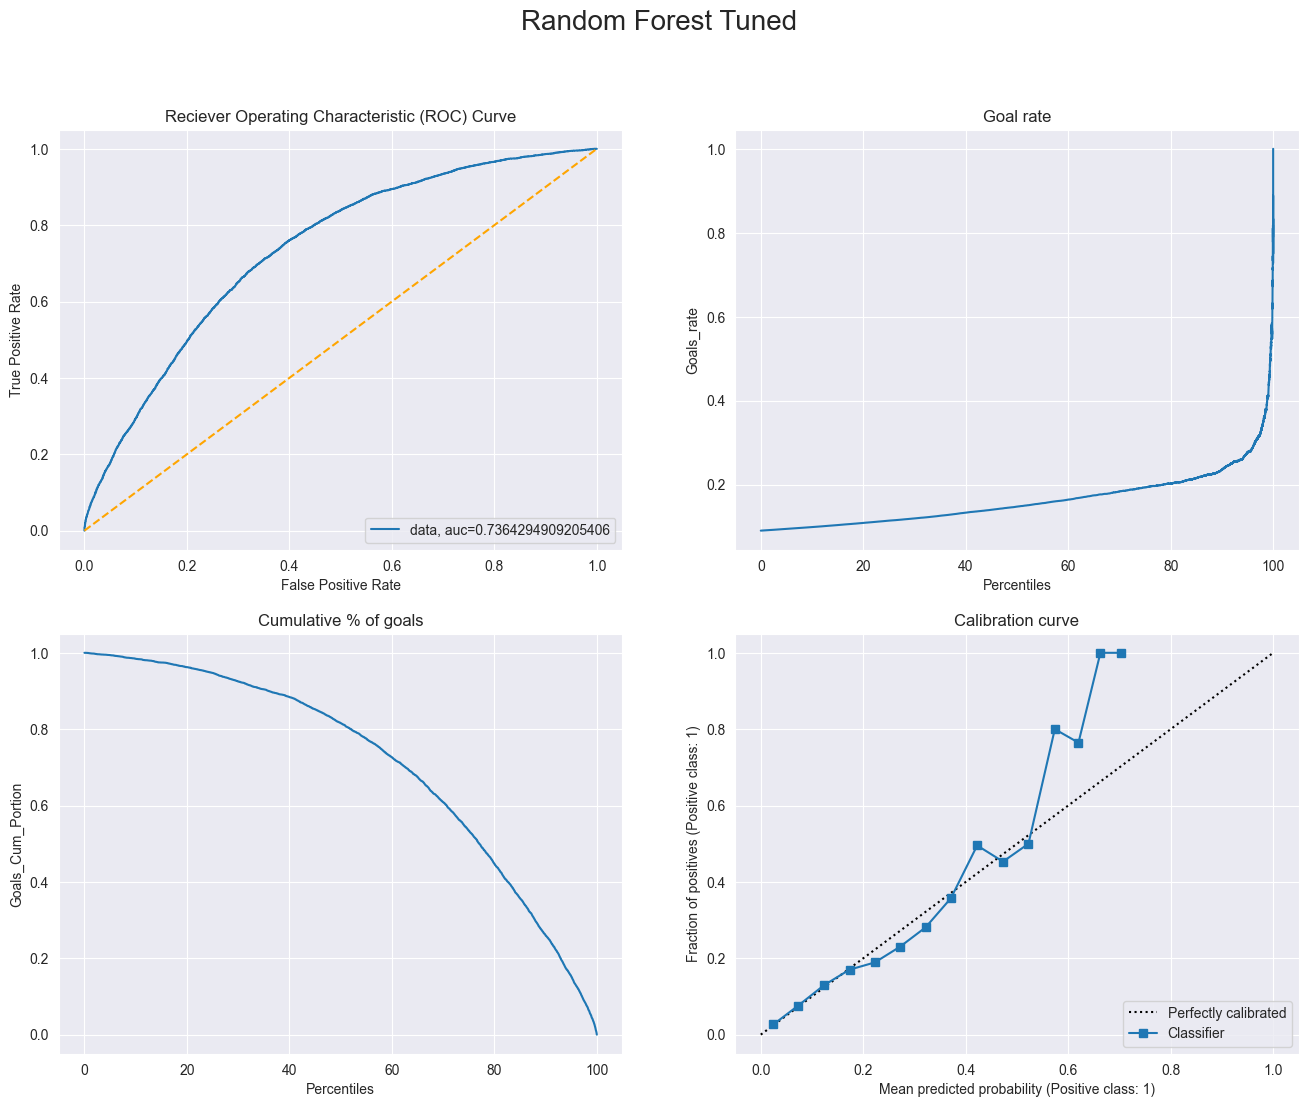

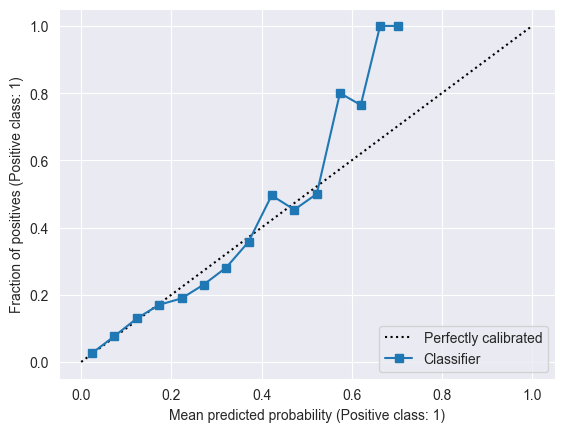

In [47]:
from sklearn.ensemble import RandomForestClassifier
exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
exp.add_tag("Random Forest Tuned")
model = RandomForestClassifier(min_samples_leaf=5, n_estimators=200)
model.fit(X_train, y_train)
print('Accuracy on training data: ', round(model.score(X_train,y_train),2))
result = model.score(X_test,y_test)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("Random Forest Tuned", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f"ece: {ece}")
auc = metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
exp.log_metric("accuracy", result)
exp.log_metric("f1_score", f1)
exp.log_metric("auc", auc)
exp.log_metric("Exp. Pred. Error", ece)
joblib.dump(model, "models/Random_Forest_Tuned.joblib")
exp.log_model("Random Forest Tuned", "models/Random_Forest_Tuned.joblib")
exp.end()

Les résultats sont comparables à la performance XGBOOST. Il semble qu'on ne peut pas faire mieux avec les forêts aléatoires.

#### Different model: Neural Network

In [ ]:
#Create a train-validation split for randomized search (if we rely on CV the search will take forever)
total = len(X_train)
indices = np.random.permutation(len(X_train))
train = int(total*0.8)
train_indices = indices[:train]
test_indices = indices [train:]
len(train_indices)+len(test_indices)

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
tuned_parameters = {
    "hidden_layer_sizes": [(100,100), (100,300), (300,100), (300,300)],
    "alpha": [0.0001, 0.001, 0.01],
    "batch_size":[100, 200, 500, 1000]
}

grid_search = RandomizedSearchCV(
    MLPClassifier(
    max_iter=50,
    activation="relu",
    solver="adam",
    #verbose=True,
    #To be tuned
    #hidden_layer_sizes=(300,100),
    #alpha = 0.0001,
    #batch_size = 100
), tuned_parameters,  scoring=my_calibration_scorer, cv=[(train_indices, test_indices)], n_iter=10,  verbose=3
)
grid_search.fit(X_train, y_train)

In [ ]:
print('Finished!')
print("Meilleur ensemble de paramètres trouvé")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé:

{'hidden_layer_sizes': (300, 100), 'batch_size': 100, 'alpha': 0.0001}
-0.0038519838403015287

In [9]:
from sklearn.neural_network import MLPClassifier
exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
exp.add_tag("Neural Network 1")
model = MLPClassifier(
    max_iter=2000,
    activation="relu",
    solver="adam",
    verbose=True,
    #To be tuned
    hidden_layer_sizes=(300,100),
    alpha = 0.0001,
    batch_size = 100
)
model.fit(X_train, y_train)
print('Accuracy on training data: ', round(model.score(X_train,y_train),2))
result = model.score(X_test,y_test)
print('Accuracy on testing data: ', round(result*100,2))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/a1f1d9d091004e339a29bfbd7468c464



Iteration 1, loss = 0.27859590
Iteration 2, loss = 0.27405430
Iteration 3, loss = 0.27299809
Iteration 4, loss = 0.27247097
Iteration 5, loss = 0.27223734
Iteration 6, loss = 0.27179171
Iteration 7, loss = 0.27160533
Iteration 8, loss = 0.27140617
Iteration 9, loss = 0.27129280
Iteration 10, loss = 0.27101187
Iteration 11, loss = 0.27088099
Iteration 12, loss = 0.27082249
Iteration 13, loss = 0.27057526
Iteration 14, loss = 0.27061414
Iteration 15, loss = 0.27032573
Iteration 16, loss = 0.27032991
Iteration 17, loss = 0.27016757
Iteration 18, loss = 0.26993046
Iteration 19, loss = 0.26995877
Iteration 20, loss = 0.26979846
Iteration 21, loss = 0.26964529
Iteration 22, loss = 0.26954138
Iteration 23, loss = 0.26950406
Iteration 24, loss = 0.26952011
Iteration 25, loss = 0.26920968
Iteration 26, loss = 0.26928265
Iteration 27, loss = 0.26909724
Iteration 28, loss = 0.26899393
Iteration 29, loss = 0.26887257
Iteration 30, loss = 0.26887620
Iteration 31, loss = 0.26874361
Iteration 32, los

f1 score: 0.4956226216088794
 ece score: 0.010726591401211178


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/a1f1d9d091004e339a29bfbd7468c464
COMET INFO:   Metrics:
COMET INFO:     Exp. Pred. Error : 0.010726591401211178
COMET INFO:     accuracy         : 0.9093480648274485
COMET INFO:     auc              : 0.7346324062629395
COMET INFO:     f1_score         : 0.4956226216088794
COMET INFO:   Parameters:
COMET INFO:     activation          : relu
COMET INFO:     alpha               : 0.0001
COMET INFO:     batch_size          : 100
COMET INFO:     beta_1              : 0.9
COMET INFO:     beta_2              : 0.999
COMET INFO:     early_stopping      : False
COMET INFO:     epsilon             : 1e-08
COMET INFO:     hidden_layer_sizes  : (300, 100)
COMET INFO:     learning_rate       : constant
COMET INFO:     learning_rate

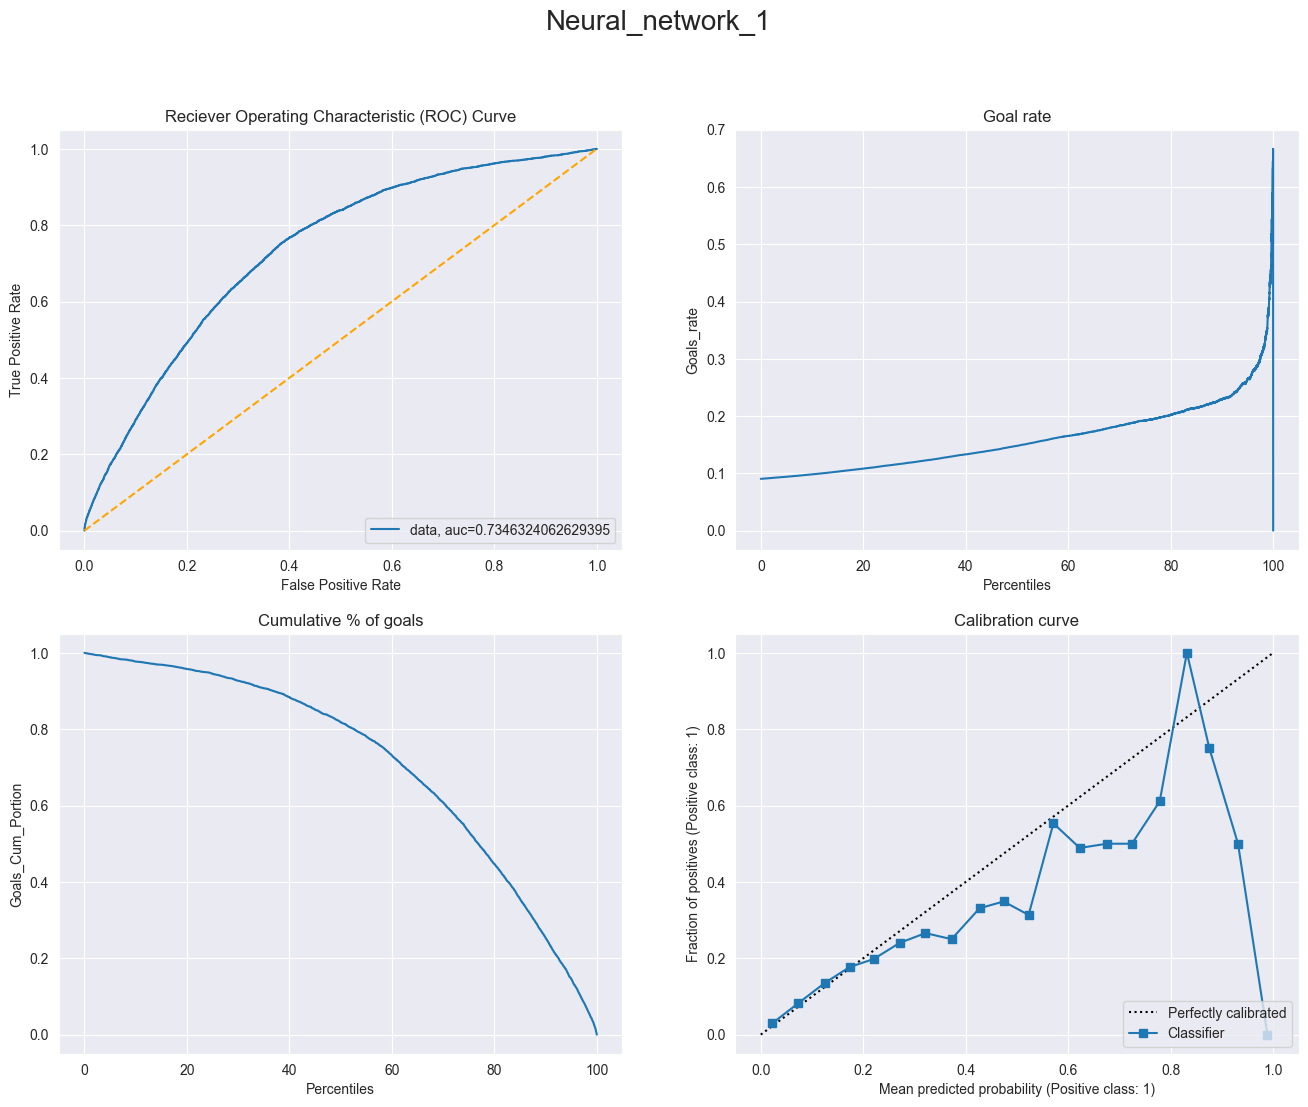

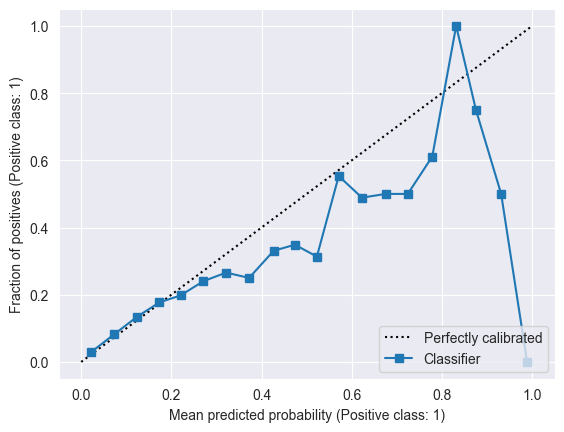

In [12]:
fig = generate_four_curves("Neural_network_1", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece score: {ece}")
auc = metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
exp.log_metric("accuracy", result)
exp.log_metric("f1_score", f1)
exp.log_metric("auc", auc)
exp.log_metric("Exp. Pred. Error", ece)
joblib.dump(model, "models/Neural_Network_1.joblib")
exp.log_model("Neural Network 1", "models/Neural_Network_1.joblib")
exp.end()

Même le réseau de neurones n'aboutit pas à un résultat meilleur. Il semble que le meilleur résultat qu'on puisse atteindre en terme de calibration en utilisant des caractérisitques sélectionnées c'est celui avec XGBOOST qui a été optimisé en utilisant ECE.